<a href="https://colab.research.google.com/github/aashnijoshi/manhattan-housing-affordability/blob/main/notebooks/02_pluto_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import matplotlib.pyplot as plt

raw = Path("../data/raw/nyc_pluto.zip")
processed = Path("../data/processed")
figures = Path("../visualizations")

processed.mkdir(exist_ok=True)
figures.mkdir(exist_ok=True)

In [2]:
columns = [
    "borough", "bbl", "block", "lot", "unitsres", "unitstotal",
    "xcoord", "ycoord", "latitude", "longitude",
    "landuse", "yearbuilt", "lotarea", "bldgarea", "version"
]

parts = []
total = 0

with ZipFile(raw) as z:
    csv_name = next(n for n in z.namelist() if n.endswith(".csv"))

    with z.open(csv_name) as f:
        for chunk in pd.read_csv(f, usecols=columns, chunksize=75000):
            total += len(chunk)
            parts.append(chunk[chunk["borough"] == "MN"])

pluto = pd.concat(parts, ignore_index=True)

print("Original NYC records:", total)
print("Non-Manhattan records removed:", total - len(pluto))
print("Manhattan records:", len(pluto))

Original NYC records: 858284
Non-Manhattan records removed: 815780
Manhattan records: 42504


In [3]:
land_use_names = {
    1: "1–2 family",
    2: "Multi-family walk-up",
    3: "Multi-family elevator",
    4: "Mixed residential / commercial",
    5: "Commercial / office",
    6: "Industrial",
    7: "Transportation / utility",
    8: "Public facilities",
    9: "Open space",
    10: "Parking",
    11: "Vacant land"
}

print("Duplicate BBLs:", pluto["bbl"].duplicated().sum())
print("Missing residential-unit counts removed:", pluto["unitsres"].isna().sum())

pluto = pluto.dropna(subset=["unitsres"]).copy()

print("Zero-unit lots retained:", (pluto["unitsres"] == 0).sum())
print("Missing coordinates:", pluto[["xcoord", "ycoord"]].isna().any(axis=1).sum())
print("Missing land-use classifications:", pluto["landuse"].isna().sum())

invalid_year = pluto["yearbuilt"].isna() | ~pluto["yearbuilt"].between(1800, 2026)
print("Invalid/missing construction years:", invalid_year.sum())

pluto["bbl"] = pluto["bbl"].astype("Int64").astype("string")
pluto["land_use_name"] = pluto["landuse"].map(land_use_names).fillna("Unclassified")

labels = [
    "1800–1899", "1900–1919", "1920–1939", "1940–1959",
    "1960–1979", "1980–1999", "2000–2026"
]

pluto["construction_period"] = (
    pd.cut(
        pluto["yearbuilt"],
        bins=[1799, 1899, 1919, 1939, 1959, 1979, 1999, 2026],
        labels=labels
    )
    .astype("string")
    .fillna("Unknown")
)

pluto.to_csv(processed / "manhattan_pluto_26v2_cleaned.csv.gz",
             index=False, compression="gzip")

print("\nCleaned Manhattan lots:", len(pluto))
print("Total residential units:", int(pluto["unitsres"].sum()))
print("Cleaned dataset saved.")

Duplicate BBLs: 0
Missing residential-unit counts removed: 63
Zero-unit lots retained: 9969
Missing coordinates: 394
Missing land-use classifications: 102
Invalid/missing construction years: 2379

Cleaned Manhattan lots: 42441
Total residential units: 958956
Cleaned dataset saved.


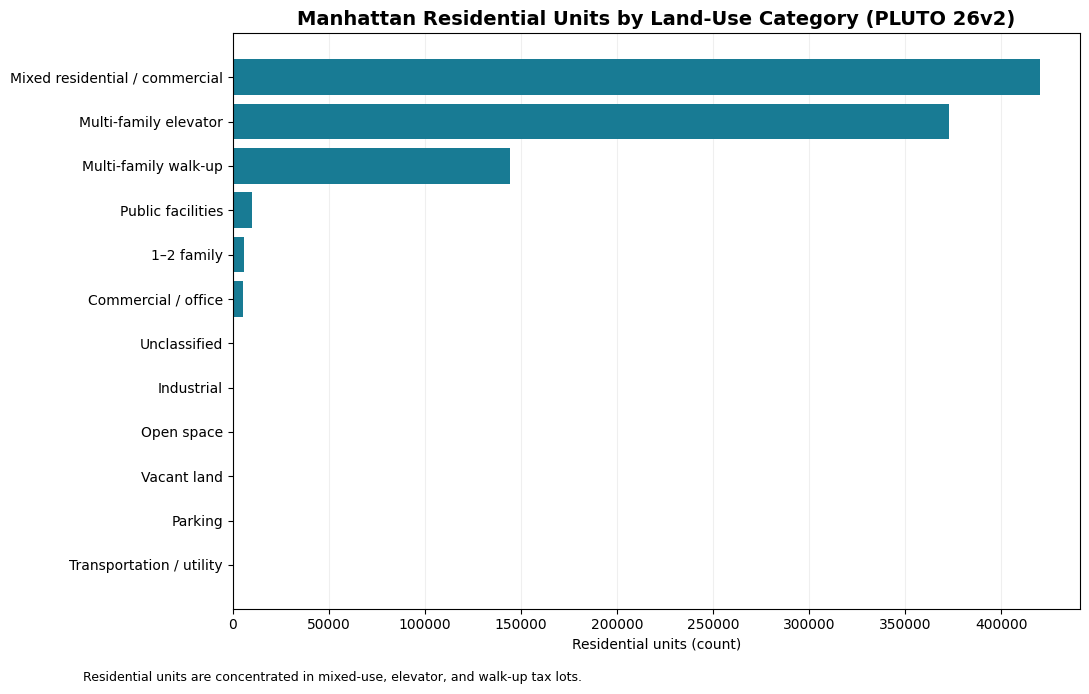

In [4]:
land_use = pluto.groupby("land_use_name")["unitsres"].sum().sort_values()

land_use.to_csv(processed / "pluto_residential_units_by_land_use.csv",
                header=["residential_units"])

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(land_use.index, land_use.values, color="#187b94")
ax.set_title("Manhattan Residential Units by Land-Use Category (PLUTO 26v2)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Residential units (count)")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(0.08, 0.02,
         "Residential units are concentrated in mixed-use, elevator, and walk-up tax lots.",
         fontsize=9)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(figures / "pluto_residential_units_by_land_use.png",
            dpi=190, bbox_inches="tight")
plt.show()

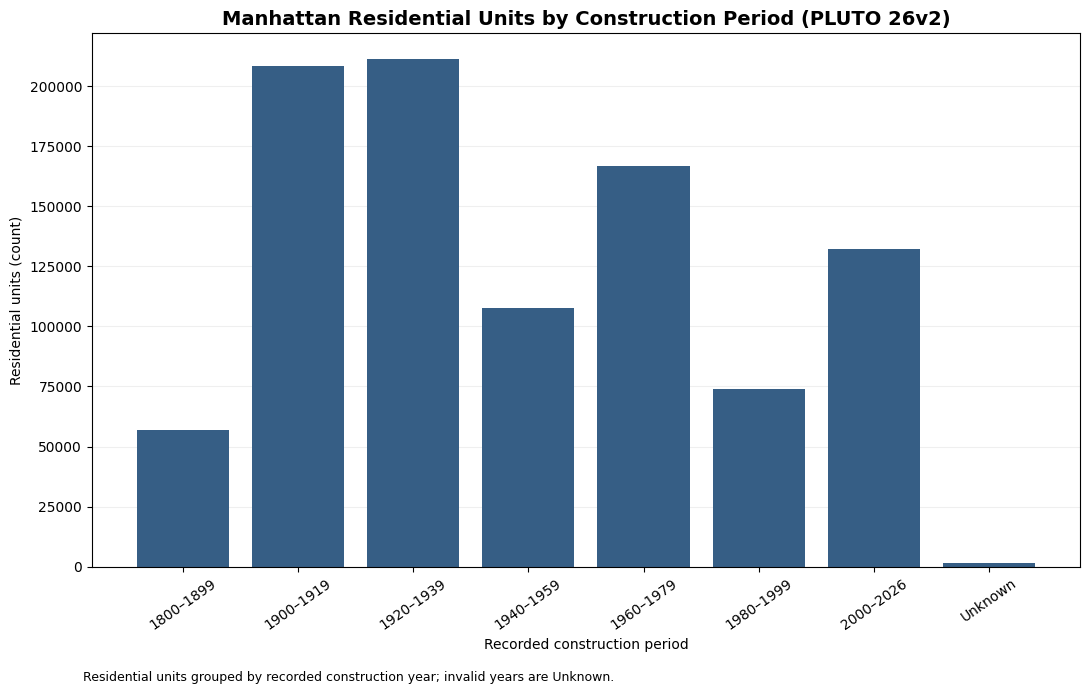

In [5]:
period_order = labels + ["Unknown"]

period = (
    pluto.groupby("construction_period")["unitsres"]
    .sum()
    .reindex(period_order, fill_value=0)
)

period.to_csv(processed / "pluto_residential_units_by_construction_period.csv",
              header=["residential_units"])

fig, ax = plt.subplots(figsize=(11, 7))

ax.bar(period.index, period.values, color="#365e85")
ax.set_title("Manhattan Residential Units by Construction Period (PLUTO 26v2)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Recorded construction period")
ax.set_ylabel("Residential units (count)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(0.08, 0.02,
         "Residential units grouped by recorded construction year; invalid years are Unknown.",
         fontsize=9)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(figures / "pluto_residential_units_by_construction_period.png",
            dpi=190, bbox_inches="tight")
plt.show()

In [6]:
for file in sorted(processed.glob("*pluto*")):
    print("Saved:", file)

for file in sorted(figures.glob("pluto_*.png")):
    print("Saved:", file)

Saved: ../data/processed/manhattan_pluto_26v2_cleaned.csv.gz
Saved: ../data/processed/pluto_cleaning_audit.csv
Saved: ../data/processed/pluto_residential_units_by_construction_period.csv
Saved: ../data/processed/pluto_residential_units_by_land_use.csv
Saved: ../visualizations/pluto_residential_units_by_construction_period.png
Saved: ../visualizations/pluto_residential_units_by_land_use.png
